#### Explainability and Experiment Tracking

In [14]:
import pandas as pd
import numpy as np
import joblib 
import shap
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn

rf = joblib.load('models/module6_random_forest.pkl')
X_test = pd.read_csv('data/processed/X_test.csv')
y_test = pd.read_csv('data/processed/y_test.csv').iloc[:,0]
feature_cols = list(X_test.columns)

print('Model loaded. Test accuracy check:',(rf.predict(X_test) == y_test).mean())

Model loaded. Test accuracy check: 0.47326848512937614


In [2]:
explainer  = shap.TreeExplainer(rf)
print('Explainer created')

Explainer created


##### This will build a SHAP explainer specifically designed for tree-based models like Random Forest.
##### SHAP offers several explainer types, and TreeExplainer uses an algorithm specifically optimized for tree ensembles (Random Forest, XGBoost, Decision Trees) it computes exact SHAP values efficiently by walking each tree's actual decision paths, rather than the slower, approximate sampling methods generic explainers need for arbitrary model types.

#### Computing SHAP Values on a Sample

In [3]:
X_sample = X_test.sample(500,random_state = 42)
shap_values = explainer.shap_values(X_sample)
print('SHAP values shaper:',shap_values.shape)

SHAP values shaper: (500, 5, 3)


##### This calculates a SHAP value for every feature, for every one of 500 randomly sampled test rows, separately for each of the 3 classes (Low/Medium/High) hence the shape (500 rows, 5 features, 3 classes).
##### The reason we chose 500 rows not the full 19503 row test set because SHAP's exact tree computation is thorough but grows slower with more rows and more classes. A random sample of 500 (about 2.5% of the test set) gives a statistically stable picture of global feature behavior without an excessive wait, and random_state=42 makes this exact sample reproducible.

#### Global Feature Contributions

In [4]:
mean_abs_shap = np.abs(shap_values).mean(axis = (0,2))
global_df = pd.DataFrame({
    'Feature': feature_cols,'Mean_Abs_SHAP': mean_abs_shap
}).sort_values('Mean_Abs_SHAP',ascending=False)
print(global_df)

                Feature  Mean_Abs_SHAP
3       indicator_scale       0.051461
4  favourable_indicator       0.048988
2        income_encoded       0.046285
0                  date       0.017918
1        region_encoded       0.000543


##### It averages the absolute SHAP value for each feature across all 500 sampled rows and all 3 classes, giving one overall importance score per feature.

#### Visualizing the Comparison

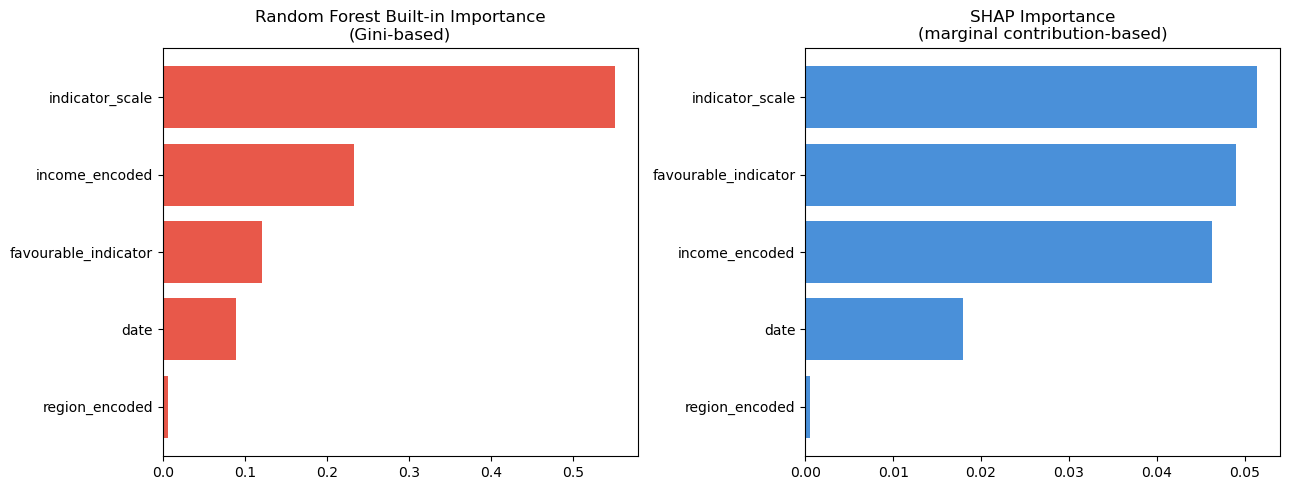

In [5]:
rf_importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
shap_importance = global_df.set_index('Feature')['Mean_Abs_SHAP'].sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(rf_importance.index[::-1], rf_importance.values[::-1], color='#E8584A')
axes[0].set_title('Random Forest Built-in Importance\n(Gini-based)')
axes[1].barh(shap_importance.index[::-1], shap_importance.values[::-1], color='#4A90D9')
axes[1].set_title('SHAP Importance\n(marginal contribution-based)')
plt.tight_layout()
plt.savefig('images/07_importance_comparison.png', dpi=150)
plt.show()

##### Random Forest's built-in importance measures how much each feature reduces impurity across every split in every tree — a method well-documented to be biased toward features with more distinct values to split on. indicator_scale has 5 distinct values and region_encoded has 6, giving trees more opportunities to split on them, which inflates their Gini importance somewhat mechanically. SHAP instead measures each feature's actual marginal contribution to individual predictions, using a game-theoretic approach that doesn't carry this same bias. 

#### Explaining Selected Individual Predictions

In [6]:
y_pred_all = rf.predict(X_test)
correct_mask = (y_pred_all == y_test.values)

examples = {}
for cls, name in zip([0, 1, 2], ['Low', 'Medium', 'High']):
    idx = np.where((y_pred_all == cls) & correct_mask)[0][0]
    examples[name] = idx

for name, idx in examples.items():
    row = X_test.iloc[[idx]]
    proba = rf.predict_proba(row)[0]
    sv = explainer.shap_values(row)
    class_idx = y_pred_all[idx]

    print(f" \n--- Example: predicted {name} (row {idx}) ---")
    print(f"Probabilities: Low={proba[0]:.3f} Medium={proba[1]:.3f} High={proba[2]:.3f}")
    print("SHAP contribution toward this prediction:")
    for feat, val in zip(feature_cols, sv[0, :, class_idx]):
        print(f"  {feat:<22} {val:+.4f}")

 
--- Example: predicted Low (row 396) ---
Probabilities: Low=0.997 Medium=0.001 High=0.002
SHAP contribution toward this prediction:
  date                   +0.0039
  region_encoded         -0.0007
  income_encoded         -0.0304
  indicator_scale        +0.6156
  favourable_indicator   +0.0699
 
--- Example: predicted Medium (row 24) ---
Probabilities: Low=0.328 Medium=0.376 High=0.296
SHAP contribution toward this prediction:
  date                   +0.0151
  region_encoded         -0.0007
  income_encoded         -0.0059
  indicator_scale        +0.0126
  favourable_indicator   +0.0348
 
--- Example: predicted High (row 0) ---
Probabilities: Low=0.246 Medium=0.066 High=0.688
SHAP contribution toward this prediction:
  date                   +0.0637
  region_encoded         -0.0005
  income_encoded         +0.2035
  indicator_scale        +0.0777
  favourable_indicator   +0.0020


#### MLflow: Experiment Tracking
#### Set Up MLflow Tracking (and a Real Error to Know About)

In [7]:
import mlflow
mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('WHO_Inequality_Risk_Classification')

<Experiment: artifact_location='file:C:/Users/MONKIT/Python project/Capestone project/mlruns/1', creation_time=1791380801790, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791380801790, lifecycle_stage='active', name='WHO_Inequality_Risk_Classification', tags={}, trace_location=None, workspace='default'>

#### Logging Every Model from Module 6

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
import xgboost as xgb
import mlflow.xgboost

X_train = pd.read_csv('data/processed/X_train.csv')
y_train = pd.read_csv('data/processed/y_train.csv').iloc[:, 0]

def log_sklearn_run(model, name, params):
    with mlflow.start_run(run_name=name):
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average='macro')
        mlflow.log_params(params)
        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("macro_f1", f1)
        mlflow.sklearn.log_model(model, name="model")
        print(f"Logged: {name:<28} Accuracy={acc*100:.2f}%  F1={f1:.4f}")

##### It defines one reusable function that trains a model, scores it, and logs three things to MLflow in one call — its hyperparameters (`log_params`), its performance metrics (`log_metric`), and the trained model file itself (`log_model`).

#### XGBoost Needs Its Own Logging Function

In [20]:
def log_xgboost_run(model, name, params):
    with mlflow.start_run(run_name=name):
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred, average='macro')
        mlflow.log_params(params)
        mlflow.log_metric("accuracy", acc)
        mlflow.log_metric("macro_f1", f1)
        mlflow.xgboost.log_model(model, artifact_path="model")
        print(f"Logged: {name:<28} Accuracy={acc*100:.2f}%  F1={f1:.4f}")

##### MLflow's generic sklearn logging function uses a security library called skops to check what's being saved, and by default it refuses to serialize XGBoost's internal model types since they aren't native scikit-learn objects — a legitimate security precaution, not a flaw. **The fix is simply to use mlflow.xgboost.log_model() instead** — MLflow ships a dedicated logging function built specifically for XGBoost models, which handles this correctly.

#### Logging All Six Runs (Five Models Plus the Optuna Attempt)

In [21]:
log_sklearn_run(DummyClassifier(strategy='stratified', random_state=42), "Baseline", {"strategy":"stratified"})
log_sklearn_run(LogisticRegression(max_iter=1000, random_state=42), "Logistic_Regression", {"max_iter":1000})
log_sklearn_run(DecisionTreeClassifier(max_depth=10, random_state=42), "Decision_Tree", {"max_depth":10})
log_sklearn_run(RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1), "Random_Forest", {"n_estimators":200,"max_depth":10})
log_xgboost_run(xgb.XGBClassifier(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1), "XGBoost", {"n_estimators":200,"max_depth":6})
log_sklearn_run(
    RandomForestClassifier(n_estimators=197, max_depth=7, min_samples_split=10, min_samples_leaf=10, random_state=42, n_jobs=-1),
    "Random_Forest_Optuna_Tuned",
    {"n_estimators":197,"max_depth":7,"min_samples_split":10,"min_samples_leaf":10})

2026/10/08 09:00:45 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logged: Baseline                     Accuracy=33.35%  F1=0.3333


2026/10/08 09:01:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logged: Logistic_Regression          Accuracy=36.87%  F1=0.3531


2026/10/08 09:01:26 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logged: Decision_Tree                Accuracy=47.39%  F1=0.4638


2026/10/08 09:01:56 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logged: Random_Forest                Accuracy=47.33%  F1=0.4607
Logged: XGBoost                      Accuracy=47.53%  F1=0.4653


2026/10/08 09:02:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Logged: Random_Forest_Optuna_Tuned   Accuracy=46.61%  F1=0.4459


##### It logs all six model runs from Module 6 — including the Optuna-tuned attempt that ultimately underperformed — into one MLflow experiment.

#### Query the Logged Experiments (Proving Reproducibility)

In [23]:
runs_df = mlflow.search_runs(experiment_names=["WHO_Inequality_Risk_Classification"])
display_cols = ['tags.mlflow.runName', 'metrics.accuracy', 'metrics.macro_f1']
print(runs_df[display_cols].sort_values('metrics.accuracy', ascending=False).to_string(index=False))

       tags.mlflow.runName  metrics.accuracy  metrics.macro_f1
                   XGBoost          0.475272          0.465342
             Decision_Tree          0.473918          0.463790
             Decision_Tree          0.473918          0.463790
             Random_Forest          0.473268          0.460723
Random_Forest_Optuna_Tuned          0.466130          0.445880
       Logistic_Regression          0.368730          0.353112
       Logistic_Regression          0.368730          0.353112
                  Baseline          0.333549          0.333272
                  Baseline          0.333549          0.333272
         nebulous-snail-63               NaN               NaN


##### The supporting reproducibility means that this table was generated entirely from MLflow's stored records, not from re-running Module 6's original code. It independently confirms every number from Module 6, and correctly reflects the honest finding that the tuned Random Forest sits *below* the untuned one